# Stack Overflow Developer Survey 2025
## Exploratory Data Analysis and Machine Learning for Perceived Productivity

This notebook analyzes the 2025 Stack Overflow Developer Survey, focusing on developers’ use of AI tools and AI agents. It includes:

- Inspection of dataset size, structure, quality, and missingness.
- Analysis of AI use by experience, role, country, and work arrangement.
- Analysis of trust, accuracy, and sentiment toward AI.
- Analysis of AI-agent use, tasks, benefits, and challenges.
- A classification model predicting whether a respondent agrees that **AI agents have increased my productivity**.

> **Important:** This target measures self-reported perceived productivity, not completed tasks or productivity measured from work records. The model explores patterns in survey responses and does not show that AI caused productivity to increase.

## Project context, dataset, and problem definition

**Dataset:** Stack Overflow Developer Survey 2025 (public respondent-level survey; CSV).  
**Source:** [Kaggle dataset page](https://www.kaggle.com/datasets/edoardogalli/stack-overflow-annual-developer-survey-2025) · [Stack Overflow Developer Survey](https://survey.stackoverflow.co/2025/).  
**Description:** The file contains voluntary survey responses from software developers and other technology professionals. It includes respondent demographics, work and coding experience, developer roles, work arrangements, technologies, and opinions and use of AI tools and AI agents. The notebook focuses on AI-agent use and respondents’ self-reported perceptions of productivity.

**Why this dataset was selected:** It is a recent, openly available, large real-world survey with a broad range of respondent and AI-related variables. It supports descriptive comparisons across experience, roles, and AI-use patterns while also allowing a carefully scoped exploratory classification exercise.

**Problem definition and questions:** The analysis asks how often respondents use AI tools and agents; how AI-related perceptions vary by experience and developer role; and what share of respondents who rated the statement “AI agents have increased my productivity” selected an agreement response (somewhat/strongly agree). Neutral and disagreement responses are coded as not positive, while no response remains missing. It also explores whether survey response patterns are associated with perceived productivity. Expected findings are differences across use-frequency groups and respondent backgrounds, alongside important limitations from voluntary self-reporting and nonresponse. These comparisons are descriptive and do not establish that AI causes productivity changes.


## 1) Data loading and setup

In [ ]:
from pathlib import Path
import io, zipfile, requests, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

DATASET_SLUG = "edoardogalli/stack-overflow-annual-developer-survey-2025"
CSV_NAME = "survey_results_public.csv"
local_candidates = [Path(CSV_NAME), Path("/kaggle/input/stack-overflow-annual-developer-survey-2025/")/CSV_NAME, Path("/kaggle/input/stack-overflow-annual-developer-survey-2025")/CSV_NAME]
file_path = next((p for p in local_candidates if p.exists()), None)
if file_path is None:
    print("CSV not found locally; downloading from Kaggle public API...")
    url = f"https://www.kaggle.com/api/v1/datasets/download/{DATASET_SLUG}"
    r = requests.get(url, timeout=120); r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        names = z.namelist()
        name = next(n for n in names if n.endswith(CSV_NAME))
        z.extract(name, ".")
        file_path = Path(name)

df_raw = pd.read_csv(file_path, low_memory=False)
print(f"File: {file_path}")
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head(5))

File: survey_results_public.csv
Shape: 49,123 rows × 170 columns


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,PurchaseInfluence,TechEndorseIntro,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,TechEndorse_8,TechEndorse_9,TechEndorse_13,TechEndorse_13_TEXT,TechOppose_1,...,AIToolPlan to mostly use AI,AIToolCurrently mostly AI,AIFrustration,AIExplain,AIAgents,AIAgentChange,AIAgent_Uses,AgentUsesGeneral,AIAgentImpactSomewhat agree,AIAgentImpactNeutral,AIAgentImpactSomewhat disagree,AIAgentImpactStrongly agree,AIAgentImpactStrongly disagree,AIAgentChallengesNeutral,AIAgentChallengesSomewhat disagree,AIAgentChallengesStrongly agree,AIAgentChallengesSomewhat agree,AIAgentChallengesStrongly disagree,AIAgentKnowledge,AIAgentKnowWrite,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning new coding techniques or programming language",Online Courses or Certification (includes all media types);Other online resources (e.g. standard...,"Yes, I learned how to use AI-enabled tools for my personal curiosity and/or hobbies",AI CodeGen tools or AI-enabled apps,14.0,"Developer, mobile",20 to 99 employees,People manager,Remote,"Yes, I influenced the purchase of a substantial addition to the tech stack",Work,10.0,7.0,9.0,6.0,3.0,11.0,12.0,1.0,8.0,14.0,NaN,15.0,...,NaN,NaN,"AI solutions that are almost right, but not quite",No,"Yes, I use AI agents at work monthly or infrequently",Not at all or minimally,Software engineering,NaN,AI agents have increased my productivity.;AI agents have reduced the time spent on specific deve...,AI agents have helped me automate repetitive tasks.;AI agents have improved the quality of my co...,NaN,NaN,NaN,I am concerned about the accuracy of the information provided by AI agents.;It takes significant...,Integrating AI agents with my existing tools and workflows can be difficult.;My company's IT and...,The cost of using certain AI agent platforms is a barrier.;I have concerns about the security an...,NaN,NaN,NaN,NaN,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning new coding techniques or programming language",Online Courses or Certification (includes all media types);Other online resources (e.g. standard...,"Yes, I learned how to use AI-enabled tools for my personal curiosity and/or hobbies",AI CodeGen tools or AI-enabled apps,10.0,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibility)",No,Personal Project,13.0,1.0,2.0,9.0,4.0,3.0,12.0,5.0,7.0,14.0,NaN,14.0,...,NaN,NaN,"AI solutions that are almost right, but not quite;Debugging AI-generated code is more time-consu...",No,"No, and I don't plan to",Not at all or minimally,NaN,NaN,NaN,NaN,NaN,NaN,NaN,It takes significant time and effort to learn how to use AI agents effectively.;The cost of usin...,NaN,I am concerned about the accuracy of the information provided by AI agents.;I have concerns abou...,Integrating AI agents with my existing tools and workflows can be difficult.;My company's IT and...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to fully understand something;When I want to learn b...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-employed",None of the above,10.0,"Yes, I am not new to coding but am learning new 

## 2) Structure and data-quality checks

Duplicate rows: 0


,dtype,missing_n,missing_pct,unique_n
AIAgentObsWrite,str,48859,99.5,195
SOTagsWant Entry,str,48693,99.1,323
SOTagsHaveEntry,str,48666,99.1,346
AIModelsWantEntry,str,48649,99.0,299
AIAgentOrchWrite,str,48646,99.0,332
JobSatPoints_15_TEXT,str,48459,98.6,571
AIAgentKnowWrite,str,48358,98.4,560
AIModelsHaveEntry,str,48348,98.4,459
SO_Actions_15_TEXT,str,48300,98.3,764
AIAgentExtWrite,str,48265,98.3,421


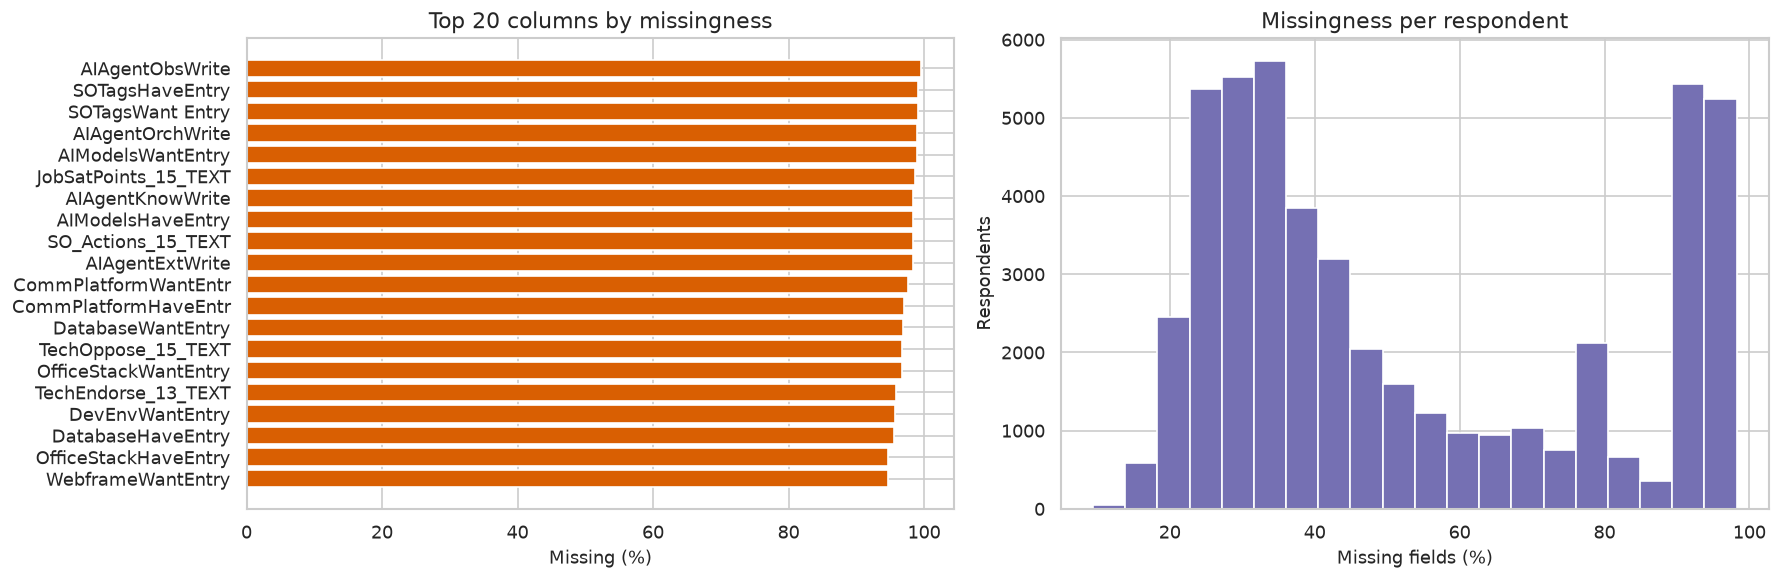

In [ ]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_n": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean()*100).round(1),
    "unique_n": df_raw.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)
print(f"Duplicate rows: {df_raw.duplicated().sum():,}")
display(quality.head(25))

fig, axes = plt.subplots(1,2,figsize=(15,5))
miss=quality.head(20).sort_values("missing_pct")
axes[0].barh(miss.index,miss.missing_pct,color="#d95f02")
axes[0].set_title("Top 20 columns by missingness"); axes[0].set_xlabel("Missing (%)")
axes[1].hist(df_raw.isna().mean(axis=1)*100,bins=20,color="#7570b3",edgecolor="white")
axes[1].set_title("Missingness per respondent"); axes[1].set_xlabel("Missing fields (%)"); axes[1].set_ylabel("Respondents")
plt.tight_layout(); plt.show()

### Required dataset-structure checks
This section explicitly displays the first five rows, dataset dimensions, column types, descriptive statistics, and missing-value counts as required by the project.

In [ ]:
print("Shape:", df_raw.shape)
print("\nData types and non-null counts:")
df_raw.info()
print("\nDescriptive statistics (numeric and categorical):")
display(df_raw.describe(include="all").T)
print("\nMissing values by column:")
display(df_raw.isnull().sum().rename("missing_count").to_frame())

Shape: (49123, 170)

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 49123 entries, 0 to 49122
Columns: 170 entries, ResponseId to JobSat
dtypes: float64(50), int64(1), str(119)
memory usage: 63.7 MB

Descriptive statistics (numeric and categorical):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ResponseId,49123.0,NaN,NaN,NaN,24562.0,14180.732974,1.0,12281.5,24562.0,36842.5,49123.0
MainBranch,49123,6,I am a developer by profession,37418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,49123,7,25-34 years old,16485,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EdLevel,48087,8,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",20247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment,48277,6,Employed,33709,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
AIAgentExtWrite,858,421,Cursor,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AIHuman,29167,574,When I don’t trust AI’s answers;When I want to fully understand something;When I want to learn b...,3046,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AIOpen,22520,20123,Problem solving,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ConvertedCompYearly,23928.0,NaN,NaN,NaN,101791.603728,461934.467776,1.0,38171.0,75383.5,120630.25,50000000.0



Missing values by column:


,missing_count
ResponseId,0
MainBranch,0
Age,0
EdLevel,1036
Employment,846
...,...
AIAgentExtWrite,48265
AIHuman,19956
AIOpen,26603
ConvertedCompYearly,25195


## 3) Data cleaning and preparation

First, remove duplicate rows and duplicate `ResponseId` records when that identifier is available, then convert experience, years coding, and compensation fields to numeric values where possible. Remove rows with a missing `ResponseId`, since records without an identifier cannot be reliably distinguished. For comparisons that require both AI-use fields, create a complete-case subset by dropping rows missing `AISelect` or `AIAgents`.

Do not drop rows with missing values across the entire wide survey: many blanks represent nonresponse or questions that do not apply, and global deletion could discard a large, biased share of respondents. The cleaned master dataset retains these values; model feature imputation is handled inside the training pipeline. Official column names are consistent with the survey codebook and the analysis code, so they are retained.

In [ ]:
df_clean = df_raw.copy()
rows_before = len(df_clean)
missing_id_before = int(df_clean["ResponseId"].isna().sum()) if "ResponseId" in df_clean.columns else 0
df_clean = df_clean.drop_duplicates().copy()
if "ResponseId" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(subset=["ResponseId"], keep="first").copy()
    # Delete records that cannot be reliably identified.
    df_clean = df_clean.dropna(subset=["ResponseId"]).copy()
for col in ["WorkExp", "YearsCode", "ConvertedCompYearly"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_clean = df_clean.reset_index(drop=True)

# Complete-case rows for analyses that specifically require both AI-use fields.
ai_required_cols = [c for c in ["AISelect", "AIAgents"] if c in df_clean.columns]
df_ai_complete = df_clean.dropna(subset=ai_required_cols).copy() if ai_required_cols else df_clean.copy()

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after duplicate and missing-ID removal: {len(df_clean):,}")
print(f"Rows removed for missing ResponseId: {missing_id_before:,}")
print(f"Duplicate rows remaining: {df_clean.duplicated().sum():,}")
print("Numeric columns converted where available: WorkExp, YearsCode, ConvertedCompYearly")
print(f"Complete-case AI-use subset after dropping missing {ai_required_cols}: {len(df_ai_complete):,} rows")
print("Other missing values are retained as survey nonresponse / not applicable; model feature imputation is performed inside the pipeline.")
display(df_clean[[c for c in ["ResponseId", "Age", "WorkExp", "YearsCode", "DevType", "AISelect"] if c in df_clean.columns]].head())

Rows before cleaning: 49,123
Rows after duplicate and missing-ID removal: 49,123
Rows removed for missing ResponseId: 0


Duplicate rows remaining: 0
Numeric columns converted where available: WorkExp, YearsCode, ConvertedCompYearly
Complete-case AI-use subset after dropping missing ['AISelect', 'AIAgents']: 31,852 rows
Other missing values are retained as survey nonresponse / not applicable; model feature imputation is performed inside the pipeline.


,ResponseId,Age,WorkExp,YearsCode,DevType,AISelect
0,1,25-34 years old,8.0,14.0,"Developer, mobile","Yes, I use AI tools monthly or infrequently"
1,2,25-34 years old,2.0,10.0,"Developer, back-end","Yes, I use AI tools weekly"
2,3,35-44 years old,10.0,12.0,"Developer, front-end","Yes, I use AI tools daily"
3,4,35-44 years old,4.0,5.0,"Developer, back-end","Yes, I use AI tools weekly"
4,5,35-44 years old,21.0,22.0,Engineering manager,"Yes, I use AI tools weekly"


## 3) Feature engineering

Convert `WorkExp` and `YearsCode` to numeric values and create indicators from survey responses. Count a response as positive only when **AI agents have increased my productivity** appears under “Somewhat agree” or “Strongly agree”; neutral and disagreement responses are coded as 0, while an unanswered target remains missing. Exclude the `AIAgentImpact*` response columns from model features to avoid using the target response itself for prediction.

In [ ]:
df=df_clean.copy()
# Numeric conversions
for col in ["WorkExp","YearsCode","ConvertedCompYearly"]:
    df[col]=pd.to_numeric(df[col],errors="coerce")

# The survey stores statement text under the selected agreement category.
# Positive = the target statement appears in either agreement category; neutral/disagreement = 0.
impact_cols=[col for col in df.columns if col.startswith("AIAgentImpact")]
target_phrase="AI agents have increased my productivity"
impact_text=df[impact_cols].fillna("").astype(str).agg(" | ".join,axis=1)
target_appears_anywhere=pd.Series(False, index=df.index)
positive_selection=pd.Series(False, index=df.index)
positive_impact_cols=[c for c in impact_cols if "somewhat agree" in c.lower() or "strongly agree" in c.lower()]
for col in impact_cols:
    selected=df[col].fillna("").astype(str).str.contains(target_phrase,case=False,regex=False)
    target_appears_anywhere |= selected
    if col in positive_impact_cols:
        positive_selection |= selected
# A statement not answered is missing, not a negative label.
df["AI_Impact_Response_Available"]=target_appears_anywhere
df["Perceived_Productivity_Positive"]=positive_selection.where(target_appears_anywhere, pd.NA).astype("Int64")
print("Positive-response categories:", positive_impact_cols)

# Multi-select features
def contains_phrase(series, phrase):
    return series.fillna("").astype(str).str.contains(phrase,case=False,regex=False).astype(int)

df["Uses_AI_Daily"]=df["AISelect"].eq("Yes, I use AI tools daily").astype(int)
df["Uses_AI_Weekly_or_more"]=df["AISelect"].isin(["Yes, I use AI tools daily","Yes, I use AI tools weekly"]).astype(int)
df["Uses_AI_Agents"]=df["AIAgents"].fillna("").str.startswith("Yes").astype(int)
df["AI_Agent_Daily"]=df["AIAgents"].eq("Yes, I use AI agents at work daily").astype(int)
df["AI_Agent_Weekly_or_more"]=df["AIAgents"].isin(["Yes, I use AI agents at work daily","Yes, I use AI agents at work weekly"]).astype(int)
df["AI_Changed_Work"]=df["AIAgentChange"].fillna("").str.startswith("Yes").astype(int)
df["Uses_LLM"]=df["AIModelsChoice"].eq("Yes").astype(int)
df["Agent_Automation_Benefit"]=contains_phrase(impact_text,"AI agents have helped me automate repetitive tasks")
df["Agent_Time_Saving_Benefit"]=contains_phrase(impact_text,"AI agents have reduced the time spent on specific development tasks")
df["AI_Frustration_Count"]=df["AIFrustration"].fillna("").str.count(";")+df["AIFrustration"].notna().astype(int)

# Normalize selected categorical values
df["DevType_Short"]=df["DevType"].fillna("Missing").str.split(",").str[0]
df["Country_Short"]=df["Country"].fillna("Missing")
df["AI_Use_Category"]=df["AISelect"].fillna("Missing")

print("Impact columns:", impact_cols)
print("Target prevalence:")
display(df["Perceived_Productivity_Positive"].value_counts(dropna=False).rename(index={0:"No",1:"Yes",pd.NA:"Missing"}).to_frame("count"))
print("Usable target rows:", df["Perceived_Productivity_Positive"].notna().sum())

Positive-response categories: ['AIAgentImpactSomewhat agree', 'AIAgentImpactStrongly agree']


Impact columns: ['AIAgentImpactSomewhat agree', 'AIAgentImpactNeutral', 'AIAgentImpactSomewhat disagree', 'AIAgentImpactStrongly agree', 'AIAgentImpactStrongly disagree']
Target prevalence:


,count
Perceived_Productivity_Positive,
Missing,36365
Yes,8768
No,3990


Usable target rows: 12758


### Optional compressed cleaned-data export

The analysis data can be saved as a compressed CSV in the project output folder. This file is not required to run the Streamlit dashboard: the app downloads the public source, reads only the required columns, and cleans/derives its fields in memory. Do not upload the large data file to GitHub unless you specifically need it and its size is suitable.

In [ ]:
from pathlib import Path
PROJECT_DIR = Path("outputs/stackoverflow_survey_2025")
APP_DIR = PROJECT_DIR / "streamlit_app"
APP_DIR.mkdir(parents=True, exist_ok=True)
# Optional compressed notebook artifact; the Streamlit app downloads and prepares the source itself.
clean_csv_path = PROJECT_DIR / "clean_data.csv.gz"
df.to_csv(clean_csv_path, index=False, compression="gzip")
print(f"Optional compressed cleaned dataset saved to: {clean_csv_path.resolve()}")
print(f"Export shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("This file is not required by app.py and does not need to be committed for the dashboard to run.")

Optional compressed cleaned dataset saved to: /home/ubuntu/stackoverflow_project/outputs/stackoverflow_survey_2025/clean_data.csv.gz
Export shape: 49,123 rows × 185 columns
This file is not required by app.py and does not need to be committed for the dashboard to run.


## 4) Overall distributions of AI use

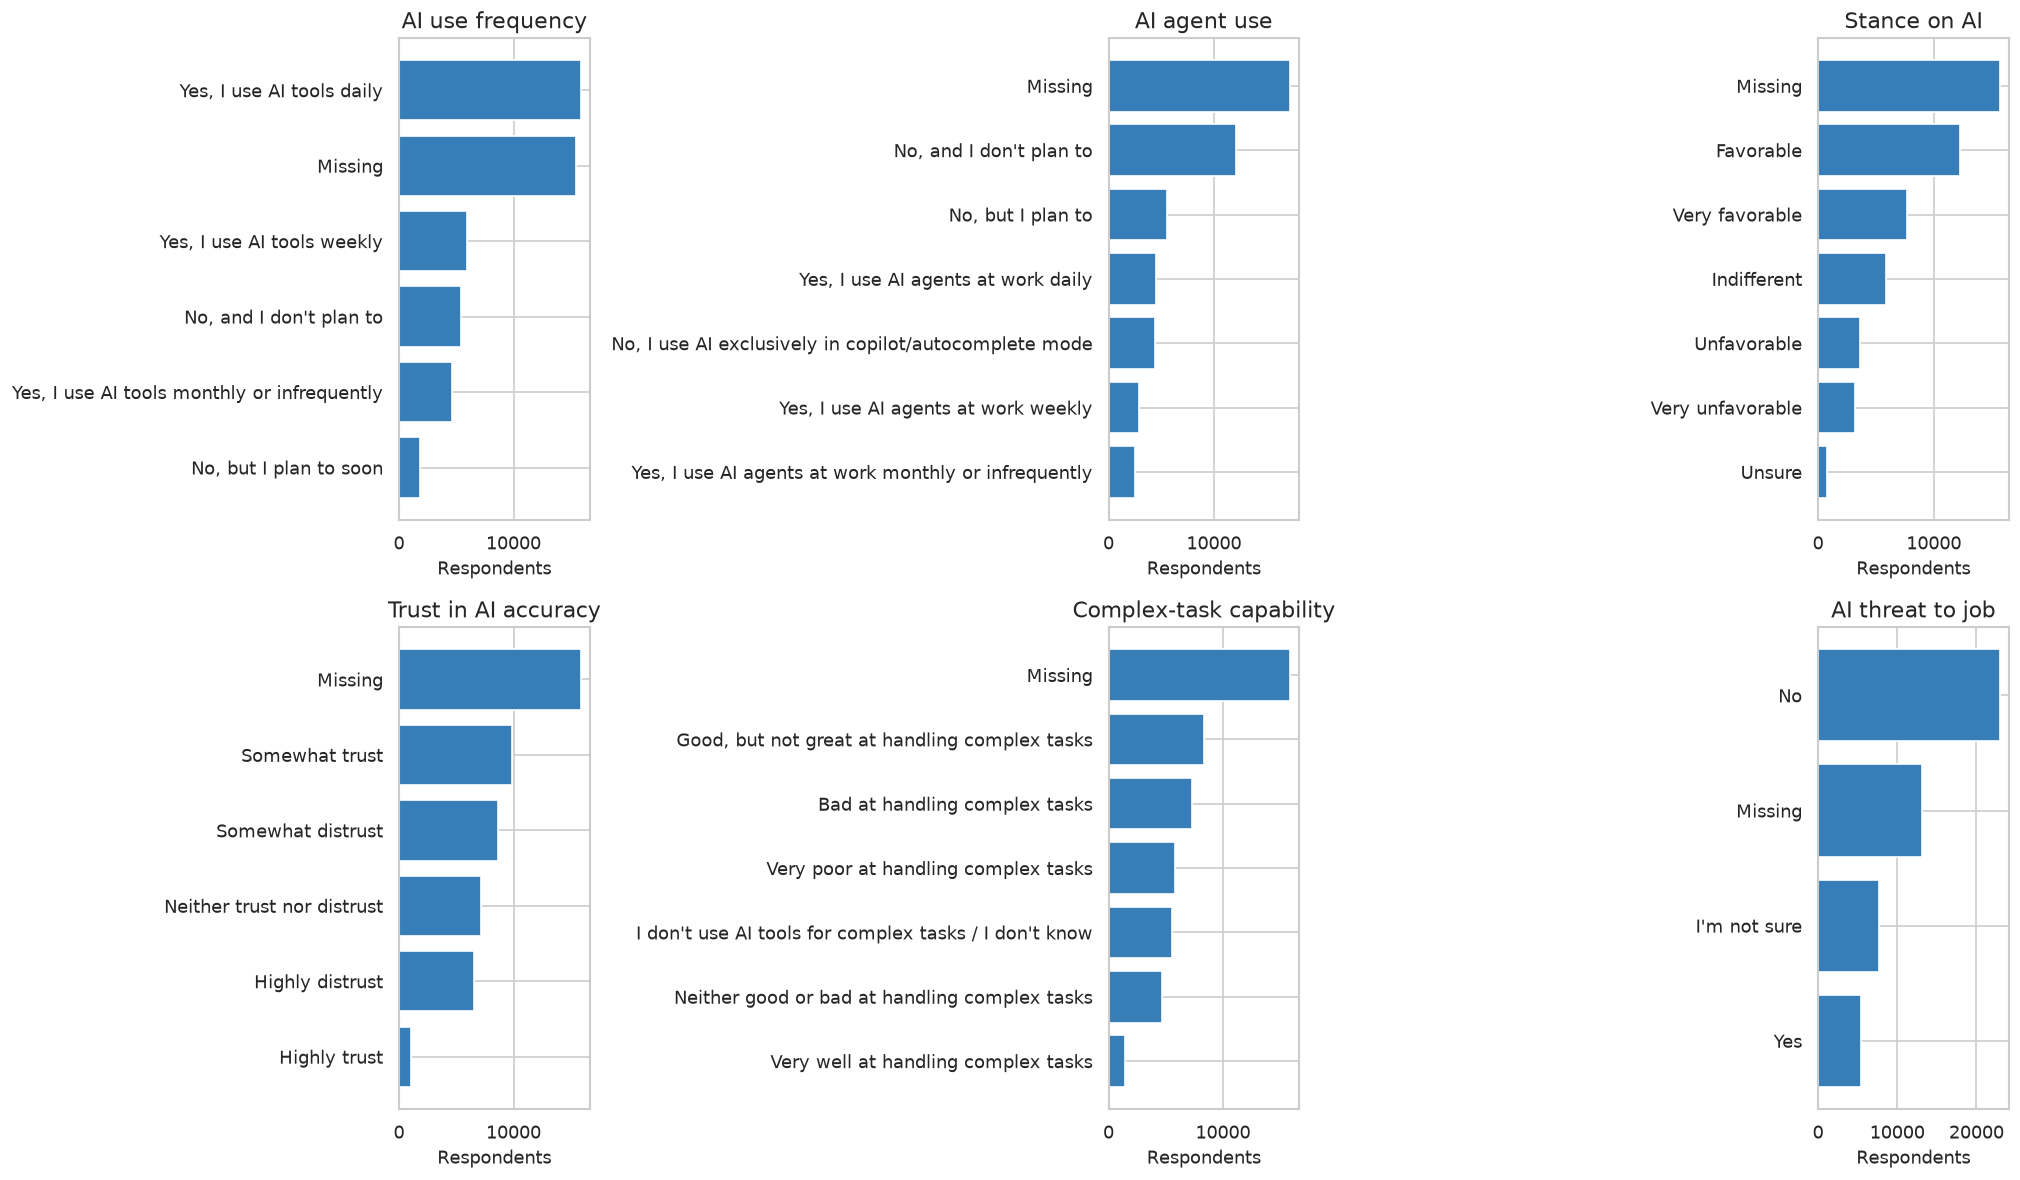

In [ ]:
fig,axes=plt.subplots(2,3,figsize=(17,10))
specs=[("AISelect","AI use frequency"),("AIAgents","AI agent use"),("AISent","Stance on AI"),("AIAcc","Trust in AI accuracy"),("AIComplex","Complex-task capability"),("AIThreat","AI threat to job")]
for ax,(col,title) in zip(axes.ravel(),specs):
    vc=df[col].fillna("Missing").value_counts().head(10).sort_values()
    ax.barh(vc.index.astype(str),vc.values,color="#377eb8")
    ax.set_title(title); ax.set_xlabel("Respondents")
plt.tight_layout(); plt.show()

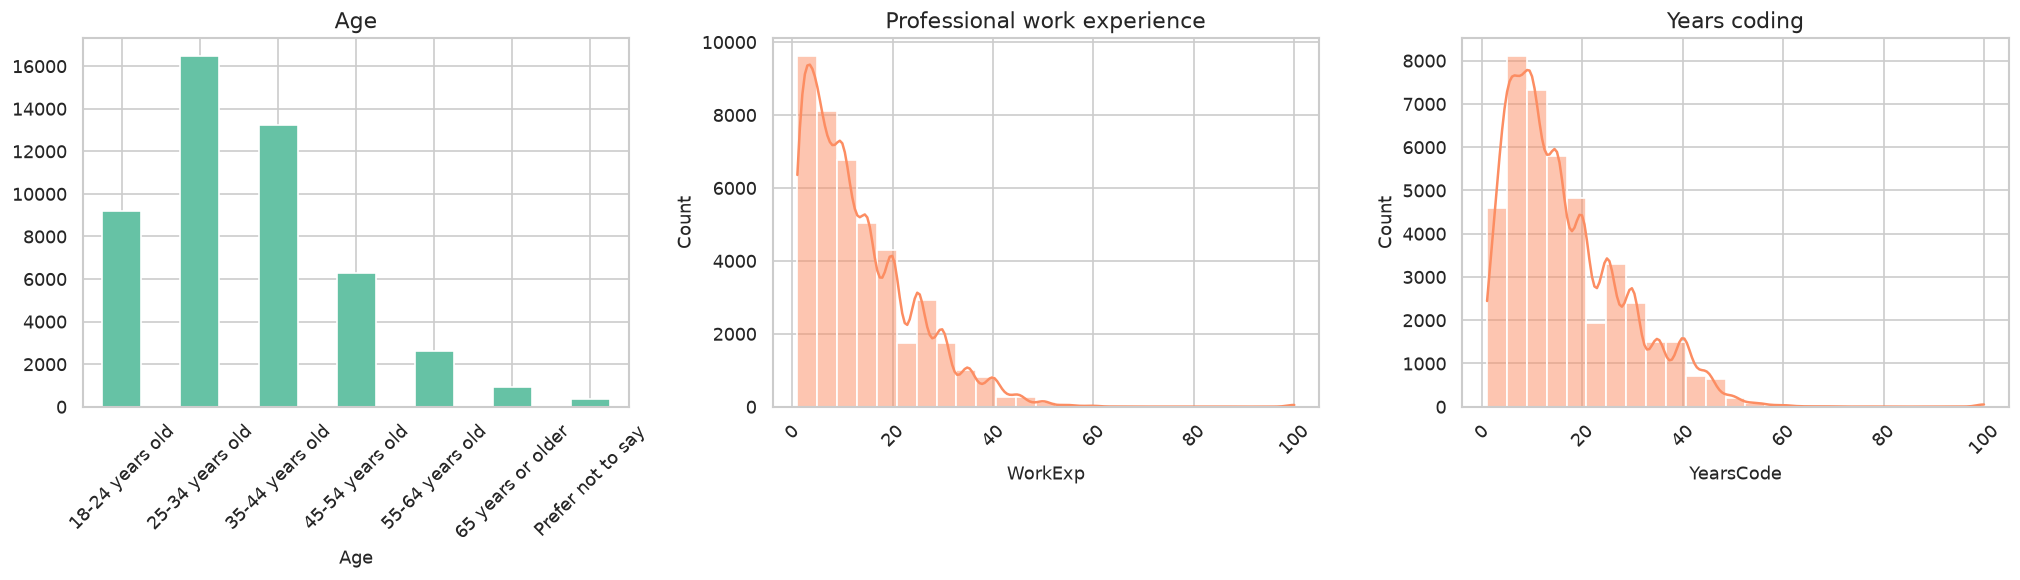

Top developer types


,count
DevType_Short,
Developer,26367
Missing,5487
Student,3003
Architect,2680
Other (please specify):,1823
Academic researcher,1129
Engineering manager,1068
DevOps engineer or professional,1053
Data engineer,769


In [ ]:
# Demographics and experience
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,col,title in zip(axes,["Age","WorkExp","YearsCode"],["Age","Professional work experience","Years coding"]):
    if col=="Age": df[col].value_counts().sort_index().plot(kind="bar",ax=ax,color="#66c2a5")
    else: sns.histplot(df[col],bins=25,kde=True,ax=ax,color="#fc8d62")
    ax.set_title(title); ax.tick_params(axis="x",rotation=45)
plt.tight_layout(); plt.show()

print("Top developer types")
display(df["DevType_Short"].value_counts().head(15).to_frame("count"))

### Countplot, boxplot, and numeric correlation heatmap
These additional plots explicitly cover the univariate count/box plots and multivariate correlation heatmap requested in the rubric. The boxplot displays potential experience outliers without deleting them.


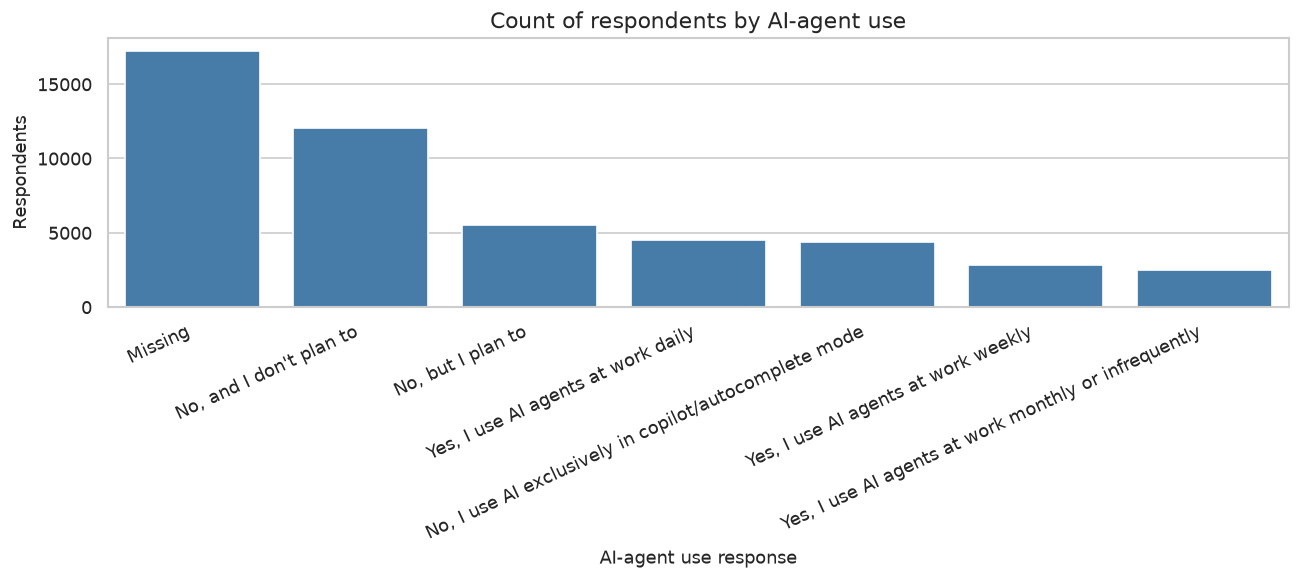

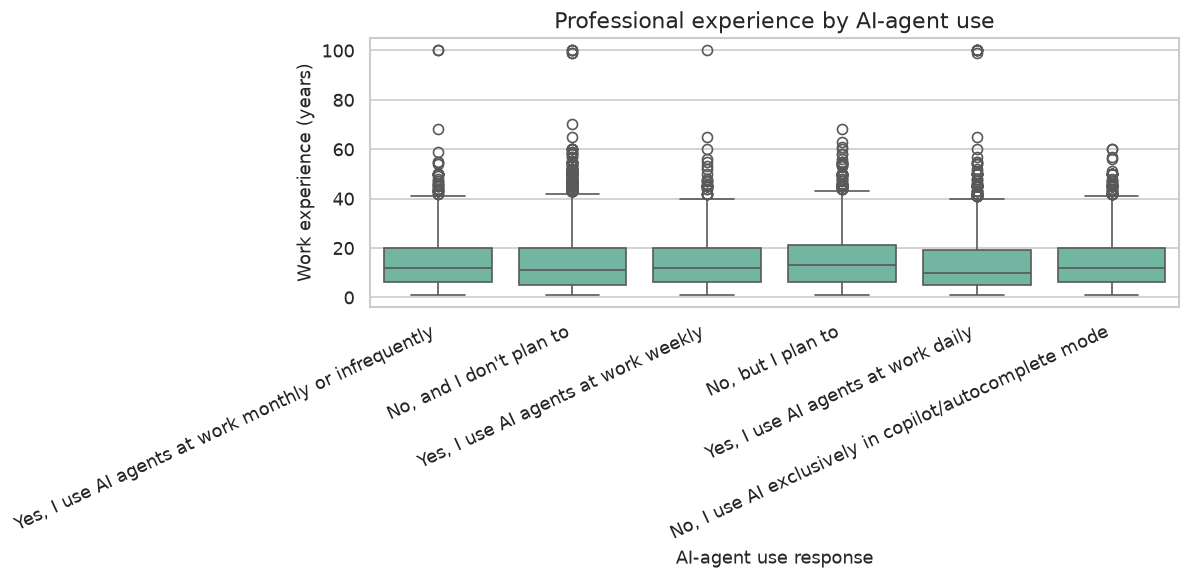

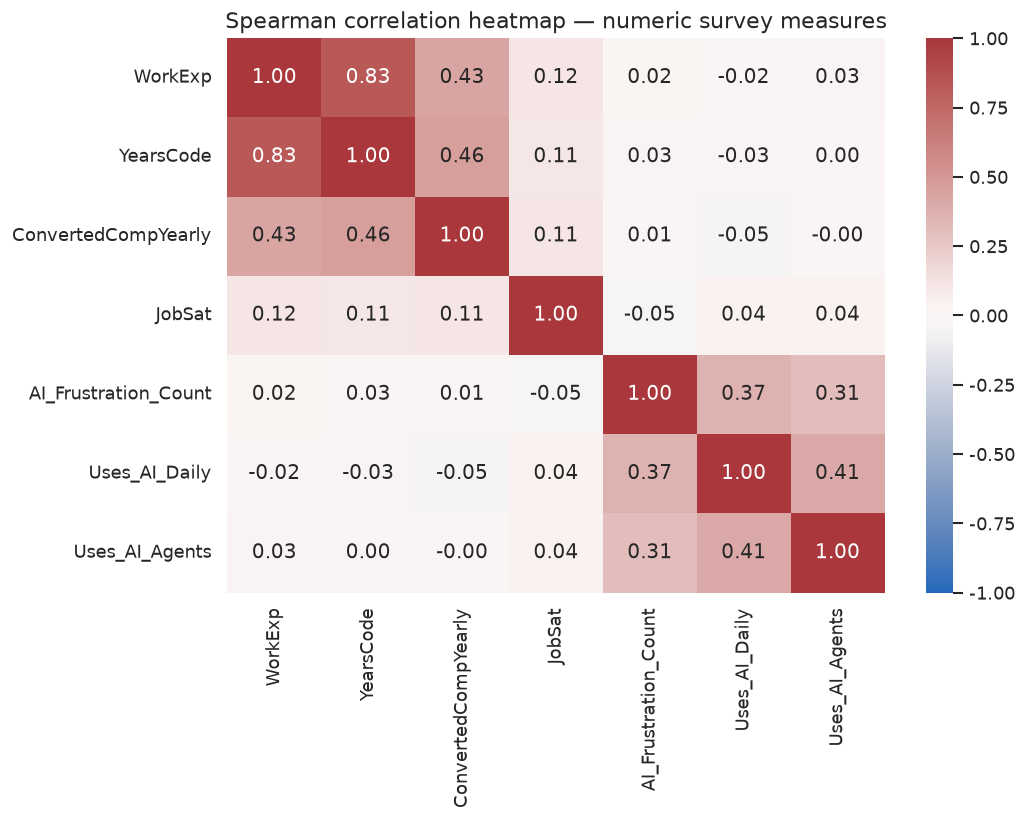

In [ ]:
# Countplot: distribution of AI-agent use responses
if "AIAgents" in df.columns:
    order=df["AIAgents"].fillna("Missing").value_counts().index
    plt.figure(figsize=(11,5))
    sns.countplot(data=df.assign(AIAgents_plot=df["AIAgents"].fillna("Missing")), x="AIAgents_plot", order=order, color="#377eb8")
    plt.title("Count of respondents by AI-agent use")
    plt.xlabel("AI-agent use response"); plt.ylabel("Respondents")
    plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

# Boxplot: experience by AI-agent use category
if {"AIAgents", "WorkExp"}.issubset(df.columns):
    box_data=df[["AIAgents", "WorkExp"]].dropna().copy()
    if len(box_data):
        plt.figure(figsize=(10,5))
        sns.boxplot(data=box_data, x="AIAgents", y="WorkExp", color="#66c2a5", showfliers=True)
        plt.title("Professional experience by AI-agent use")
        plt.xlabel("AI-agent use response"); plt.ylabel("Work experience (years)")
        plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

# Correlation heatmap for numeric survey measures (Spearman rank correlations)
corr_candidates=["WorkExp", "YearsCode", "ConvertedCompYearly", "JobSat", "AI_Frustration_Count", "Uses_AI_Daily", "Uses_AI_Agents"]
corr_cols=[c for c in corr_candidates if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(corr_cols) >= 2:
    corr=df[corr_cols].corr(method="spearman", numeric_only=True)
    plt.figure(figsize=(9,7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
    plt.title("Spearman correlation heatmap — numeric survey measures")
    plt.tight_layout(); plt.show()
else:
    print("Not enough numeric columns are available for the correlation heatmap.")

## 5) Relationships between AI use and perceived productivity

,count,mean,rate_pct
AISelect,,,
"Yes, I use AI tools daily",8405,0.79881,79.9
"Yes, I use AI tools weekly",2369,0.590122,59.0
Missing,19,0.526316,52.6
"No, but I plan to soon",292,0.407534,40.8
"Yes, I use AI tools monthly or infrequently",1429,0.330301,33.0
"No, and I don't plan to",244,0.22541,22.5


,count,mean,rate_pct
AIAgents,,,
"Yes, I use AI agents at work daily",4052,0.891905,89.2
"Yes, I use AI agents at work weekly",2596,0.751541,75.2
Missing,86,0.581395,58.1
"Yes, I use AI agents at work monthly or infrequently",2254,0.524845,52.5
"No, I use AI exclusively in copilot/autocomplete mode",3770,0.522546,52.3


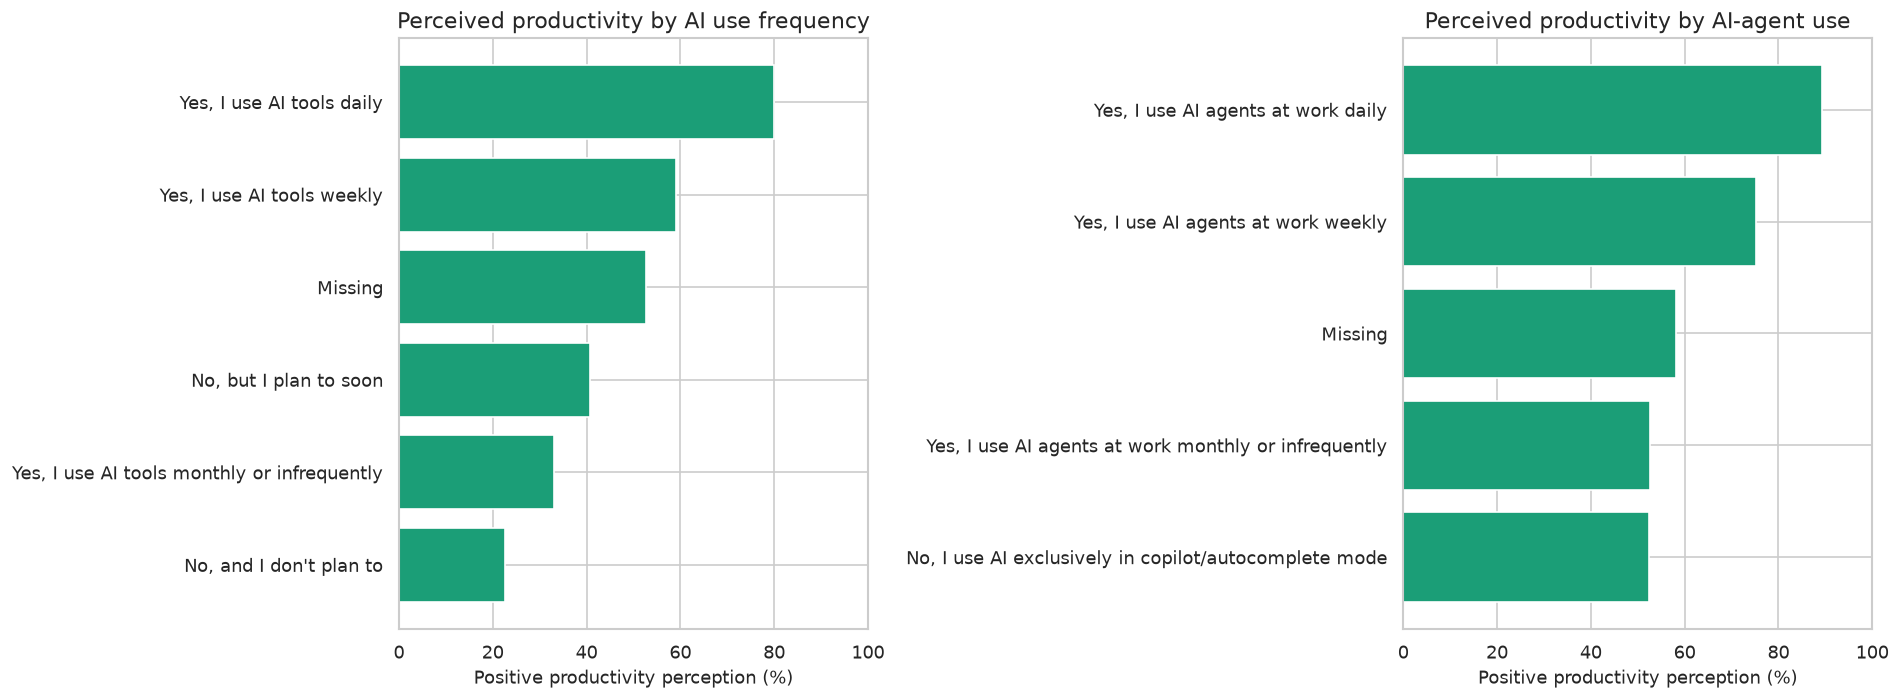

In [ ]:
usable=df[df["Perceived_Productivity_Positive"].notna()].copy()
# Rates by AI usage and agent usage
def rate_table(col):
    tmp=usable.copy(); tmp[col]=tmp[col].fillna("Missing")
    return tmp.groupby(col)["Perceived_Productivity_Positive"].agg(["count","mean"]).assign(rate_pct=lambda x:(x["mean"]*100).round(1)).sort_values("rate_pct",ascending=False)

display(rate_table("AISelect"))
display(rate_table("AIAgents"))

fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax,col,title in zip(axes,["AISelect","AIAgents"],["Perceived productivity by AI use frequency","Perceived productivity by AI-agent use"]):
    t=rate_table(col).sort_values("rate_pct")
    ax.barh(t.index.astype(str),t.rate_pct,color="#1b9e77")
    ax.set_title(title); ax.set_xlabel("Positive productivity perception (%)"); ax.set_xlim(0,100)
plt.tight_layout(); plt.show()

,count,mean,rate_pct
WorkExp_Band,,,
0–2,1125,0.736889,73.7
3–5,1855,0.722372,72.2
6–10,2705,0.7061,70.6
11–20,3628,0.678335,67.8
20+,2695,0.642301,64.2


,count,mean,rate_pct
DevType_Short,,,
Founder,162,0.765432,76.5
Data engineer,227,0.722467,72.2
Senior executive (C-suite,228,0.719298,71.9
Engineering manager,400,0.7175,71.8
AI/ML engineer,262,0.709924,71.0
Architect,956,0.695607,69.6
Data or business analyst,100,0.69,69.0
Student,700,0.688571,68.9
Developer,7782,0.683629,68.4


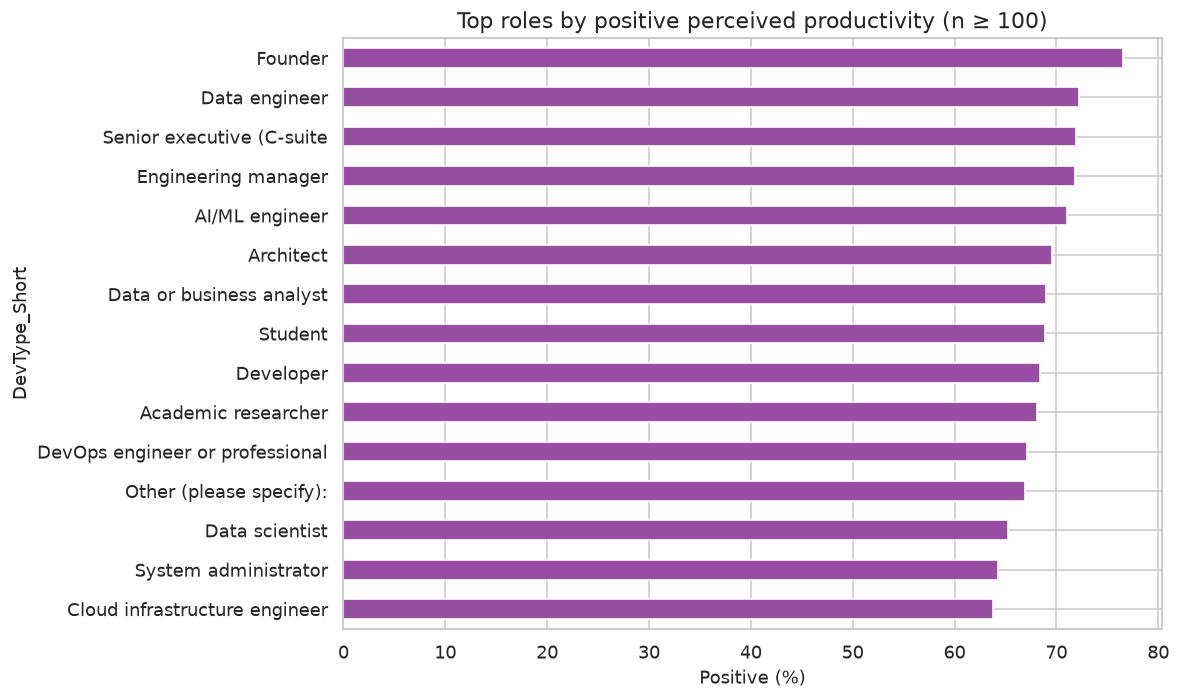

In [ ]:
# Experience bands and role comparison
usable["WorkExp_Band"]=pd.cut(usable["WorkExp"],[-np.inf,2,5,10,20,np.inf],labels=["0–2","3–5","6–10","11–20","20+"])
exp=usable.groupby("WorkExp_Band",observed=False)["Perceived_Productivity_Positive"].agg(["count","mean"]).assign(rate_pct=lambda x:(x["mean"]*100).round(1))
display(exp)
role=usable.groupby("DevType_Short")["Perceived_Productivity_Positive"].agg(["count","mean"]).query("count >= 100").assign(rate_pct=lambda x:(x["mean"]*100).round(1)).sort_values("rate_pct",ascending=False)
display(role.head(15))
role[["rate_pct"]].head(15).sort_values("rate_pct").plot(kind="barh",figsize=(10,6),color="#984ea3",legend=False)
plt.title("Top roles by positive perceived productivity (n ≥ 100)"); plt.xlabel("Positive (%)"); plt.tight_layout(); plt.show()

## 6) Trust, accuracy, and benefits

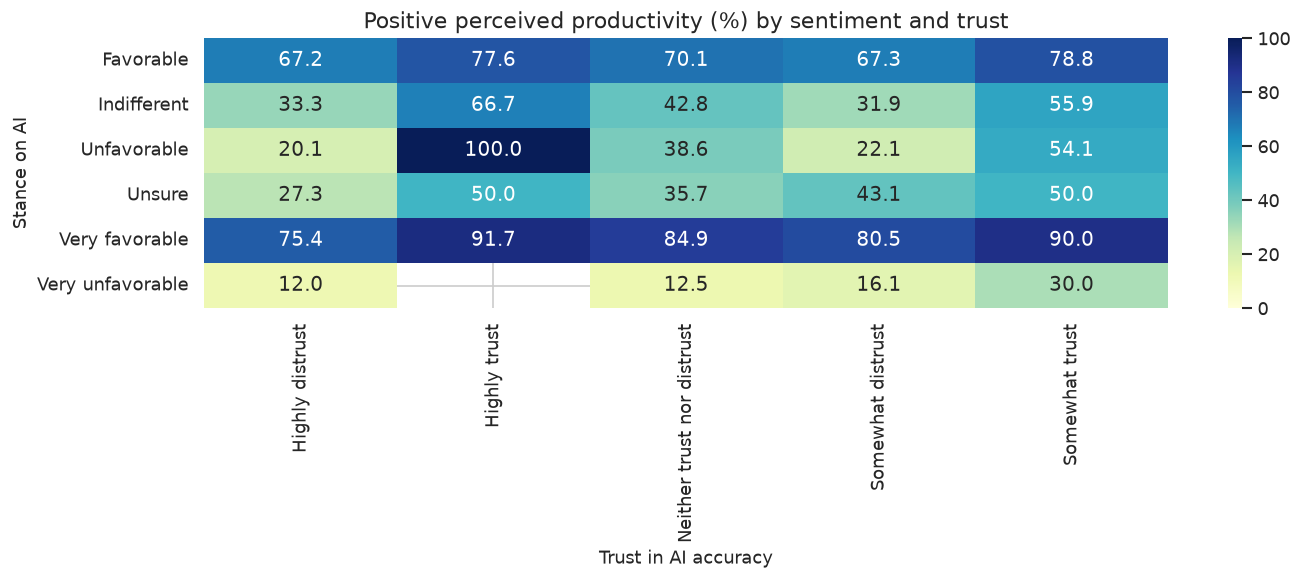

Feature rates among target-available rows:


,percent
Agent_Automation_Benefit,98.7
Agent_Time_Saving_Benefit,98.0
AI_Changed_Work,72.5
AI_Agent_Daily,31.8
AI_Agent_Weekly_or_more,52.1
Perceived_Productivity_Positive,68.7


In [ ]:
# Cross-tab heatmap: AI sentiment × AI accuracy trust
ct=pd.crosstab(usable["AISent"],usable["AIAcc"],values=usable["Perceived_Productivity_Positive"],aggfunc="mean")*100
ct=ct.astype(float)
plt.figure(figsize=(12,5)); sns.heatmap(ct,annot=True,fmt=".1f",cmap="YlGnBu",vmin=0,vmax=100)
plt.title("Positive perceived productivity (%) by sentiment and trust"); plt.xlabel("Trust in AI accuracy"); plt.ylabel("Stance on AI"); plt.tight_layout(); plt.show()

benefit_cols=["Agent_Automation_Benefit","Agent_Time_Saving_Benefit","AI_Changed_Work","AI_Agent_Daily","AI_Agent_Weekly_or_more"]
print("Feature rates among target-available rows:")
display(usable[benefit_cols+['Perceived_Productivity_Positive']].mean().mul(100).round(1).to_frame("percent"))

### Professional experience vs. years coding (scatter plot)
Each point represents a respondent; a fixed-size sample is used for readability when the plot is dense. This is a descriptive association, not evidence of causation.

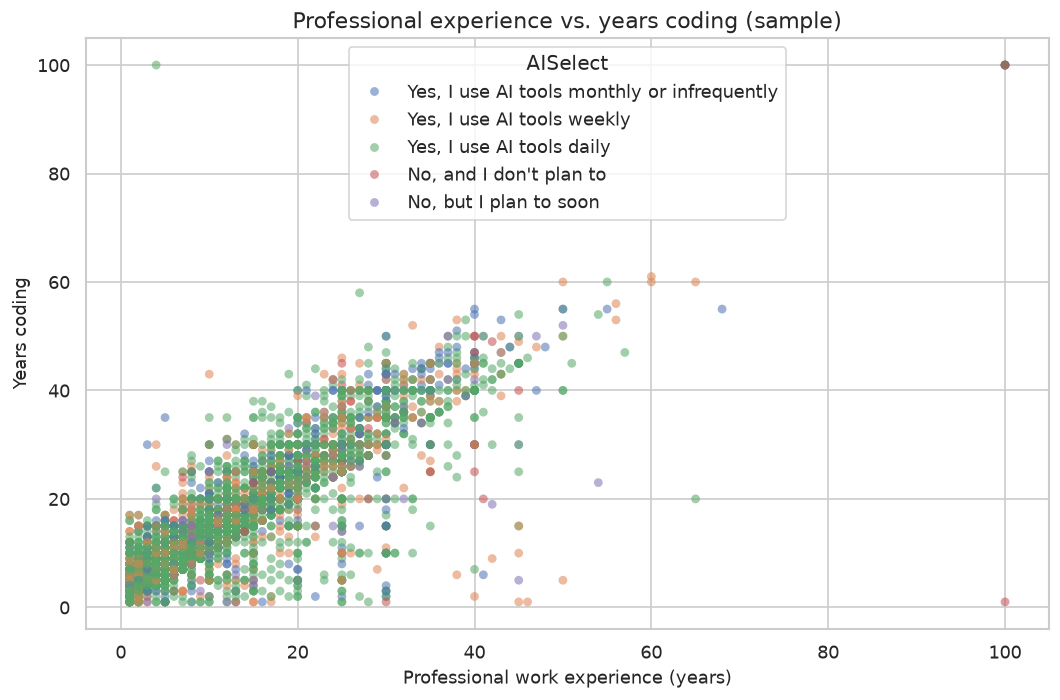

In [ ]:
scatter_cols=[c for c in ["WorkExp", "YearsCode", "AISelect"] if c in usable.columns]
scatter_data=usable[scatter_cols].dropna(subset=[c for c in ["WorkExp", "YearsCode"] if c in scatter_cols]).copy()
if len(scatter_data) > 5000:
    scatter_data=scatter_data.sample(5000, random_state=42)
if {"WorkExp", "YearsCode"}.issubset(scatter_data.columns):
    plt.figure(figsize=(9,6))
    sns.scatterplot(data=scatter_data, x="WorkExp", y="YearsCode", hue="AISelect" if "AISelect" in scatter_data else None,
                    alpha=.55, s=28, linewidth=0)
    plt.title("Professional experience vs. years coding (sample)")
    plt.xlabel("Professional work experience (years)")
    plt.ylabel("Years coding")
    plt.tight_layout(); plt.show()
else:
    print("WorkExp and YearsCode are not both available; scatter plot skipped.")

## 7) Machine-learning model

**Task:** Classify respondents as `Positive` or `Not positive` using AI-use and background information. Exclude the `AIAgentImpact*` response columns and variables derived directly from the target (`Agent_Automation_Benefit` and `Agent_Time_Saving_Benefit`) to reduce target leakage.

Use Logistic Regression with one-hot encoding and compare it with a `DummyClassifier` baseline. Metrics include balanced accuracy, ROC-AUC, and F1 because the outcome classes are imbalanced.


Dummy baseline
Accuracy: 0.687
Balanced accuracy: 0.500
F1 positive: 0.815
ROC-AUC: 0.500
              precision    recall  f1-score   support

Not positive       0.00      0.00      0.00       998
    Positive       0.69      1.00      0.81      2192

    accuracy                           0.69      3190
   macro avg       0.34      0.50      0.41      3190
weighted avg       0.47      0.69      0.56      3190


Logistic Regression
Accuracy: 0.767
Balanced accuracy: 0.759
F1 positive: 0.822
ROC-AUC: 0.842
              precision    recall  f1-score   support

Not positive       0.60      0.74      0.66       998
    Positive       0.87      0.78      0.82      2192

    accuracy                           0.77      3190
   macro avg       0.74      0.76      0.74      3190
weighted avg       0.78      0.77      0.77      3190



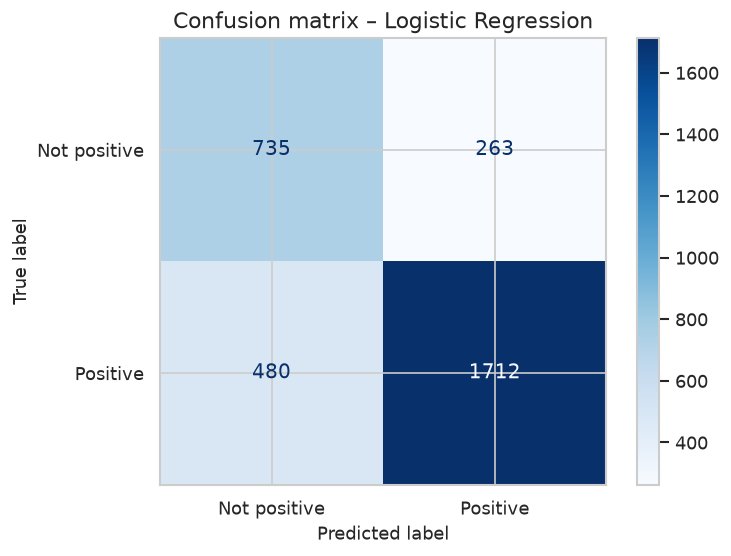

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score, roc_auc_score, f1_score, accuracy_score

model_df=usable.copy()
# Features selected before observing the productivity statement
feature_cols=[
    "AISelect","AISent","AIAcc","AIComplex","AIAgents","AIAgentChange","AIThreat",
    "AIModelsChoice","Age","WorkExp","YearsCode","DevType_Short","OrgSize","RemoteWork","EdLevel","Employment"
]
feature_cols=[c for c in feature_cols if c in model_df.columns]
X=model_df[feature_cols].copy(); y=model_df["Perceived_Productivity_Positive"].astype(int)
cat_cols=[c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols=[c for c in X.columns if c not in cat_cols]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
pre=ColumnTransformer([
    ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),num_cols),
    ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat_cols)
])
logit=Pipeline([("preprocess",pre),("model",LogisticRegression(max_iter=500,class_weight="balanced"))])
baseline=DummyClassifier(strategy="most_frequent")
logit.fit(X_train,y_train); baseline.fit(X_train,y_train)

def evaluate(name,model):
    pred=model.predict(X_test); proba=model.predict_proba(X_test)[:,1] if hasattr(model,"predict_proba") else None
    print(f"\n{name}")
    print(f"Accuracy: {accuracy_score(y_test,pred):.3f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test,pred):.3f}")
    print(f"F1 positive: {f1_score(y_test,pred):.3f}")
    if proba is not None: print(f"ROC-AUC: {roc_auc_score(y_test,proba):.3f}")
    print(classification_report(y_test,pred,target_names=["Not positive","Positive"]))
    return pred,proba

pred_base,_=evaluate("Dummy baseline",baseline)
pred,proba=evaluate("Logistic Regression",logit)
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["Not positive","Positive"],cmap="Blues")
plt.title("Confusion matrix – Logistic Regression"); plt.tight_layout(); plt.show()

## 8) Model interpretation

Review the features with the largest model coefficients. These are not causal effects; they indicate which variables help distinguish outcomes within this sample.

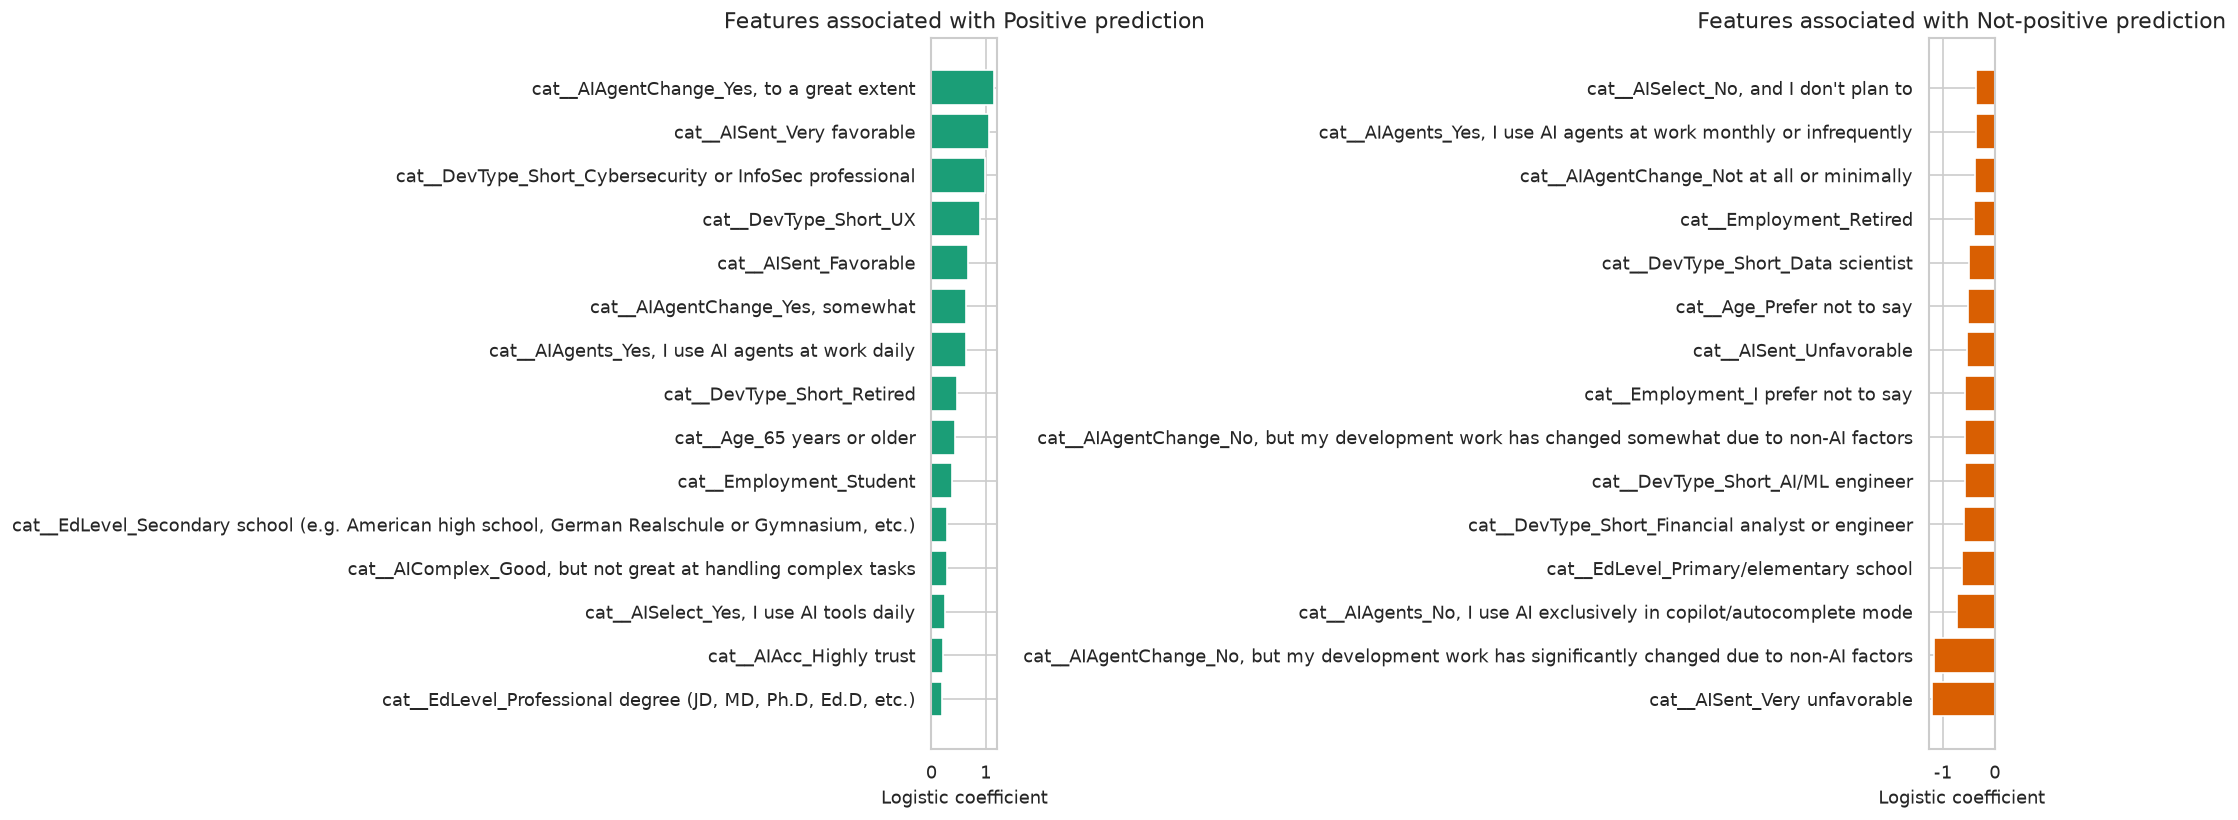

,feature,coefficient,abs_coef
12,cat__AISent_Very unfavorable,-1.213084,1.213084
29,"cat__AIAgentChange_No, but my development work has significantly changed due to non-AI factors",-1.177038,1.177038
32,"cat__AIAgentChange_Yes, to a great extent",1.158734,1.158734
11,cat__AISent_Very favorable,1.069201,1.069201
50,cat__DevType_Short_Cybersecurity or InfoSec professional,0.994739,0.994739
68,cat__DevType_Short_UX,0.891731,0.891731
24,"cat__AIAgents_No, I use AI exclusively in copilot/autocomplete mode",-0.732137,0.732137
7,cat__AISent_Favorable,0.681078,0.681078
31,"cat__AIAgentChange_Yes, somewhat",0.639677,0.639677
25,"cat__AIAgents_Yes, I use AI agents at work daily",0.637902,0.637902


In [ ]:
feature_names=logit.named_steps["preprocess"].get_feature_names_out()
coefs=logit.named_steps["model"].coef_[0]
coef_df=pd.DataFrame({"feature":feature_names,"coefficient":coefs})
coef_df["abs_coef"]=coef_df.coefficient.abs()
top_pos=coef_df.sort_values("coefficient",ascending=False).head(15).sort_values("coefficient")
top_neg=coef_df.sort_values("coefficient",ascending=True).head(15)
fig,axes=plt.subplots(1,2,figsize=(17,7))
axes[0].barh(top_pos.feature,top_pos.coefficient,color="#1b9e77"); axes[0].set_title("Features associated with Positive prediction")
axes[1].barh(top_neg.feature,top_neg.coefficient,color="#d95f02"); axes[1].set_title("Features associated with Not-positive prediction")
for ax in axes: ax.set_xlabel("Logistic coefficient")
plt.tight_layout(); plt.show()
display(coef_df.sort_values("abs_coef",ascending=False).head(25))

## Final summary and conclusions

- **Patterns and relationships:** Review the rates and plots above. The code summary reports the positive-response share and groups with the highest and lowest observed rates among available responses. These are descriptive differences, not causal effects.
- **Potential outliers:** The IQR screening flags potential compensation outliers but does not remove them automatically; high salaries may be real, and currencies and work arrangements differ.
- **What we learned:** Do not treat nonresponse as a negative response. Productivity in this dataset is self-reported rather than operationally measured.
- **Limitations:** The survey is voluntary and cross-sectional, with nonresponse and potential selection/self-reporting bias. Associations do not establish that AI caused productivity changes. Model performance applies to this sample and split; it is not suitable for hiring or individual performance decisions.
- **Future work:** Use longitudinal or task-level data, consider survey weights and sensitivity analyses where available, and validate results on independent subgroups.

> **Remaining project deliverables:** Export the PDF using the required structure, prepare a 5–7 minute presentation with seven slides, and upload the project files and README to GitHub. The notebook can generate the Streamlit app; the app downloads and prepares the public survey data at runtime and does not require a checked-in cleaned CSV.

## Create the interactive Streamlit app

The following cell creates `app.py`. At runtime, the app downloads the public survey file from Kaggle, reads only the required columns, removes duplicates, converts numeric fields, and derives the perceived-productivity indicator in memory. It does not require `clean_data.csv`, so the large file does not need to be committed to GitHub. Streamlit caches the prepared data for 24 hours. The deployment environment must have internet access to download the source.

From the app directory, install dependencies and launch the dashboard with `pip install -r requirements.txt` and `streamlit run app.py`. The sidebar includes the dataset description, country and AI-use filters, and an experience slider; the main page shows a preview, summary statistics, interactive charts, and insights.

In [ ]:
app_code = r'''import io
import zipfile

import pandas as pd
import plotly.express as px
import requests
import streamlit as st


st.set_page_config(page_title="Stack Overflow 2025 — AI Insights", layout="wide")

DATASET_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "edoardogalli/stack-overflow-annual-developer-survey-2025"
)
TARGET_PHRASE = "AI agents have increased my productivity"

# Only read fields used by this dashboard, plus the AI-agent impact response columns.
# This keeps memory use much lower than loading the full 170-column survey.
REQUIRED_COLUMNS = {
    "ResponseId",
    "Country",
    "Age",
    "DevType",
    "WorkExp",
    "YearsCode",
    "AISelect",
    "AIAgents",
    "ConvertedCompYearly",
    "JobSat",
}


@st.cache_data(ttl=24 * 60 * 60, show_spinner="Downloading and preparing the public survey data…")
def load_and_clean_data():
    """Download the public survey ZIP, load relevant columns, and clean in memory."""
    response = requests.get(DATASET_URL, timeout=(20, 180))
    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        csv_name = next(
            name for name in archive.namelist()
            if name.endswith("survey_results_public.csv")
        )
        with archive.open(csv_name) as csv_file:
            data = pd.read_csv(
                csv_file,
                low_memory=False,
                usecols=lambda column: (
                    column in REQUIRED_COLUMNS or column.startswith("AIAgentImpact")
                ),
            )

    # Basic cleaning: remove duplicate records and convert numeric fields safely.
    data = data.drop_duplicates().copy()
    if "ResponseId" in data.columns:
        data = data.drop_duplicates(subset=["ResponseId"], keep="first").copy()
    for column in ["WorkExp", "YearsCode", "ConvertedCompYearly", "JobSat"]:
        if column in data.columns:
            data[column] = pd.to_numeric(data[column], errors="coerce")

    # In the survey, each statement is stored in the response-category column
    # chosen by the respondent. Agreement is positive; neutral/disagreement is
    # not positive. If the statement was not answered, keep the target missing.
    impact_columns = [
        column for column in data.columns
        if column.startswith("AIAgentImpact")
    ]
    statement_selected = pd.Series(False, index=data.index)
    positive_selected = pd.Series(False, index=data.index)
    agreement_columns = [
        column for column in impact_columns
        if "somewhat agree" in column.lower() or "strongly agree" in column.lower()
    ]
    for column in impact_columns:
        selected = data[column].fillna("").astype(str).str.contains(
            TARGET_PHRASE, case=False, regex=False
        )
        statement_selected |= selected
        if column in agreement_columns:
            positive_selected |= selected

    data["Perceived_Productivity_Positive"] = (
        positive_selected.where(statement_selected, pd.NA).astype("Int64")
    )
    data["Country_Short"] = data.get("Country", pd.Series("Missing", index=data.index)).fillna("Missing")
    data["AI_Use_Category"] = data.get("AISelect", pd.Series("Missing", index=data.index)).fillna("Missing")
    return data.reset_index(drop=True)


st.title("Stack Overflow Developer Survey 2025")
st.subheader("AI tools, AI agents, and perceived productivity")
st.sidebar.header("Dataset and filters")
st.sidebar.write(
    "The app downloads the public 2025 survey and prepares the required fields in memory. "
    "No cleaned CSV needs to be stored in this repository. Productivity is self-reported; "
    "comparisons are descriptive, not causal."
)
st.sidebar.caption("Source: Kaggle public dataset — Stack Overflow Developer Survey 2025")

try:
    df = load_and_clean_data()
except Exception as exc:
    st.error(
        "The survey data could not be downloaded. Check the app's internet connection "
        "and try again. The app retrieves the public dataset from Kaggle at runtime."
    )
    st.exception(exc)
    st.stop()

st.success(f"Loaded and cleaned {len(df):,} survey responses in memory.")
filtered = df

if "Country_Short" in filtered.columns:
    countries = sorted(filtered["Country_Short"].dropna().astype(str).unique())
    selected_country = st.sidebar.selectbox("Country", ["All"] + countries)
    if selected_country != "All":
        filtered = filtered[filtered["Country_Short"].astype(str) == selected_country]

if "AI_Use_Category" in filtered.columns:
    categories = sorted(filtered["AI_Use_Category"].dropna().astype(str).unique())
    selected_ai = st.sidebar.multiselect(
        "AI-use frequency", categories, default=categories
    )
    filtered = filtered[filtered["AI_Use_Category"].astype(str).isin(selected_ai)]

if "WorkExp" in filtered.columns and filtered["WorkExp"].notna().any():
    low = max(0, int(filtered["WorkExp"].min()))
    high = max(low, int(filtered["WorkExp"].max()))
    if low < high:
        experience_range = st.sidebar.slider(
            "Professional experience (years)", low, high, (low, high)
        )
        filtered = filtered[
            filtered["WorkExp"].between(experience_range[0], experience_range[1])
        ]

st.header("Filtered dataset")
st.caption(f"{len(filtered):,} respondents match the selected filters.")
preview_columns = [
    column for column in [
        "Country", "Age", "DevType", "WorkExp", "YearsCode", "AISelect",
        "AIAgents", "Perceived_Productivity_Positive",
    ] if column in filtered.columns
]
st.dataframe(
    filtered[preview_columns].head(25) if preview_columns else filtered.head(25),
    use_container_width=True,
)

left, right = st.columns(2)
with left:
    st.subheader("Summary statistics")
    numeric_columns = [
        column for column in ["WorkExp", "YearsCode", "ConvertedCompYearly", "JobSat"]
        if column in filtered.columns
    ]
    if numeric_columns:
        st.dataframe(filtered[numeric_columns].describe().T, use_container_width=True)
    else:
        st.info("No selected numeric columns are available.")

with right:
    st.subheader("AI-use frequency")
    if "AI_Use_Category" in filtered.columns:
        counts = (
            filtered["AI_Use_Category"].value_counts(dropna=False)
            .rename_axis("AI use").reset_index(name="Respondents")
        )
        st.plotly_chart(
            px.bar(counts, x="AI use", y="Respondents", title="Respondents by AI-use frequency"),
            use_container_width=True,
        )

st.subheader("Perceived productivity by AI-agent use")
if {"AIAgents", "Perceived_Productivity_Positive"}.issubset(filtered.columns):
    valid = filtered.dropna(subset=["AIAgents", "Perceived_Productivity_Positive"])
    if len(valid):
        rates = (
            valid.groupby("AIAgents")["Perceived_Productivity_Positive"]
            .agg(["mean", "count"]).reset_index()
        )
        rates["Positive perception (%)"] = rates["mean"] * 100
        st.plotly_chart(
            px.bar(
                rates, x="AIAgents", y="Positive perception (%)",
                hover_data=["count"],
                title="Share agreeing that AI agents increased productivity",
            ),
            use_container_width=True,
        )
        overall_rate = valid["Perceived_Productivity_Positive"].astype(float).mean() * 100
        st.info(
            f"Among respondents with a valid answer, {overall_rate:.1f}% agreed. "
            "This is self-reported and does not show a causal effect."
        )
    else:
        st.info("No valid productivity-impact answers remain under these filters.")
else:
    st.info("Required AI-agent response fields are not available in this dataset.")

if {"WorkExp", "YearsCode"}.issubset(filtered.columns):
    st.subheader("Experience and years coding")
    plot_data = filtered.dropna(subset=["WorkExp", "YearsCode"])
    if len(plot_data) > 5000:
        plot_data = plot_data.sample(5000, random_state=42)
    st.plotly_chart(
        px.scatter(
            plot_data, x="WorkExp", y="YearsCode",
            color="AI_Use_Category" if "AI_Use_Category" in plot_data else None,
            opacity=0.55,
            title="Professional experience vs. years coding (sample)",
        ),
        use_container_width=True,
    )
'''
app_path = APP_DIR / "app.py"
app_path.write_text(app_code, encoding="utf-8")
print(f"Streamlit app created: {app_path.resolve()}")
print("The app downloads the public survey and cleans the required fields in memory; no clean_data.csv is required.")
print("Run: streamlit run outputs/stackoverflow_survey_2025/streamlit_app/app.py")

Streamlit app created: /home/ubuntu/stackoverflow_project/outputs/stackoverflow_survey_2025/streamlit_app/app.py
The app downloads the public survey and cleans the required fields in memory; no clean_data.csv is required.
Run: streamlit run outputs/stackoverflow_survey_2025/streamlit_app/app.py
